In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("CUDA device name:", torch.cuda.get_device_name(0))

PyTorch version: 2.12.0+cu130
CUDA version: 13.0
CUDA available: True
CUDA device name: NVIDIA GeForce RTX 5060 Laptop GPU


In [ ]:
from pathlib import Path

BASE_DIR = Path(r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\train-yolo26")
DATA_DIR = Path(r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai")
yaml_path = DATA_DIR / "data.yaml"

print("BASE_DIR :", BASE_DIR)
print("DATA_DIR :", DATA_DIR)
print("YAML     :", yaml_path)



BASE_DIR : D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING
DATA_DIR : D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai
YAML     : D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\data.yaml


In [16]:
with open(yaml_path, "r") as f:
    print(f.read())

names:
- bus
- mobil
- motor
- truk
nc: 4
roboflow:
  license: CC BY 4.0
  project: pengembangan-ai-cctv
  url: https://universe.roboflow.com/kp-kominfo/pengembangan-ai-cctv/dataset/6
  version: 6
  workspace: kp-kominfo
test: D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\test\images
train: D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\train\images
val: D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\valid\images



In [17]:
from ultralytics import YOLO
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

model = YOLO("yolo26n.pt")

results = model.train(
    data=str(yaml_path),
    epochs=100,
    imgsz=640,
    batch=16,
    patience=20, # Early stopping patience (number of epochs with no improvement after which training will be stopped)
    name="yolo26-cctv",
    project=str(BASE_DIR / "runs"),
    device=0,
    workers=0
)

CUDA available: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
New https://pypi.org/project/ultralytics/8.4.72 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.52  Python-3.11.9 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.

In [19]:
# Load model with best results
from ultralytics import YOLO
from pathlib import Path

best_model_path = BASE_DIR / "runs" / "yolo26-cctv" / "weights" / "best.pt"

model = YOLO(str(best_model_path))

print("Model berhasil diload:")
print(best_model_path)

Model berhasil diload:
D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\runs\yolo26-cctv\weights\best.pt


In [ ]:
# validasi model dengan data validasi
etrics = model.val(
    data=str(yaml_path),
    imgsz=640,
    batch=8,
    device=0,
    workers=0
)

Ultralytics 8.4.52  Python-3.11.9 torch-2.12.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
YOLO26n summary (fused): 122 layers, 2,375,616 parameters, 0 gradients, 5.2 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 1119.7254.8 MB/s, size: 97.2 KB)
val: Scanning D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\valid\labels.cache... 100 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 100/100  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 6.7it/s 2.0s0.2s
                   all        100       5077       0.93      0.841      0.922      0.729
                   bus         30         32          1      0.886      0.956      0.892
                 mobil        100       2251      0.921       0.87      0.949      0.727
                 motor        100       2600      0.904      0.777      0.881      0.577
                  truk         93        194      0.895       0.83      0.9

In [21]:
# prediksi dengan data test
results = model.predict(
    source=str(DATA_DIR / "test" / "images"),
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project=str(BASE_DIR / "runs"),
    name="predict-yolo26-test"
)


image 1/50 D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\test\images\100_jpg.rf.f00db277e5a60d666783de63fddde014.jpg: 640x640 1 bus, 25 mobils, 38 motors, 16.8ms
image 2/50 D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\test\images\102_jpg.rf.1e389faac9add9d9551e582fbfc6dba8.jpg: 640x640 1 bus, 22 mobils, 36 motors, 1 truk, 13.5ms
image 3/50 D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\test\images\105_jpg.rf.bc56f8cf2bcb370ae08bb887cfbd0108.jpg: 640x640 1 bus, 24 mobils, 23 motors, 4 truks, 12.9ms
image 4/50 D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\test\images\30_jpg.rf.1d6ce4ee01f8b5a2478d868285d2fc0c.jpg: 640x640 2 buss, 12 mobils, 19 motors, 3 truks, 10.5ms
image 5/50 D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\test\images\33_jpg.rf.270678d15342129e5ea569a6ae48b333.jpg: 640x640 1 bus, 18 mobils, 44 motors, 12.5ms
image 6/50 D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\data-cctv-ai\test\images

# Visualisasi Hasil Train Model YOLO

In [63]:
import os

print("Isi folder hasil training:")

for nama_file in os.listdir(run_dir):
    print(nama_file)

Isi folder hasil training:
args.yaml
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
labels.jpg
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
train_batch5940.jpg
train_batch5941.jpg
train_batch5942.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights


## results.png

Grafik ringkasan hasil training, seperti loss, precision, recall, mAP50, mAP50-95, dan learning rate.

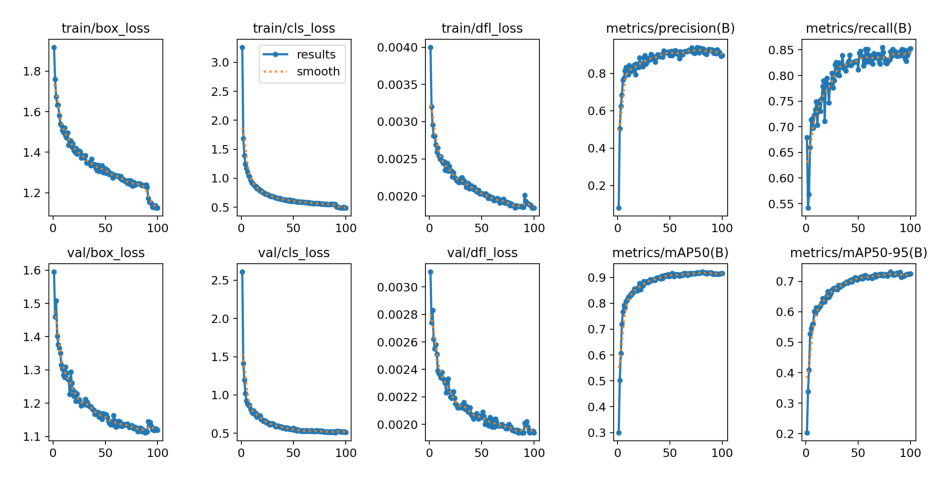

## confusion_matrix.png

Confusion matrix yang menunjukkan kesalahan dan kebenaran klasifikasi antar kelas.

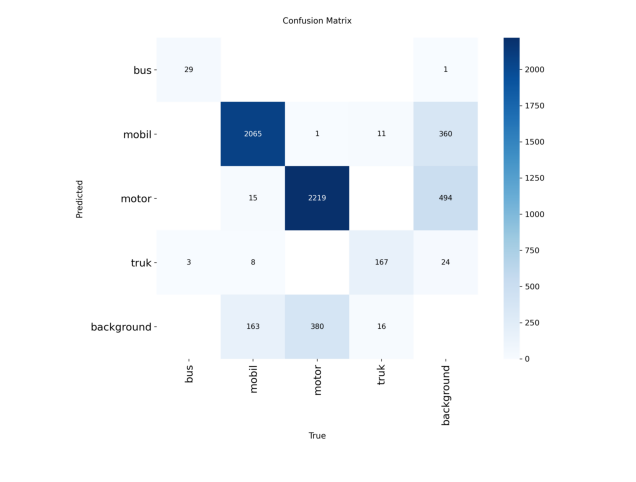

## confusion_matrix_normalized.png

Confusion matrix dalam bentuk normalisasi agar lebih mudah melihat proporsi kesalahan tiap kelas.

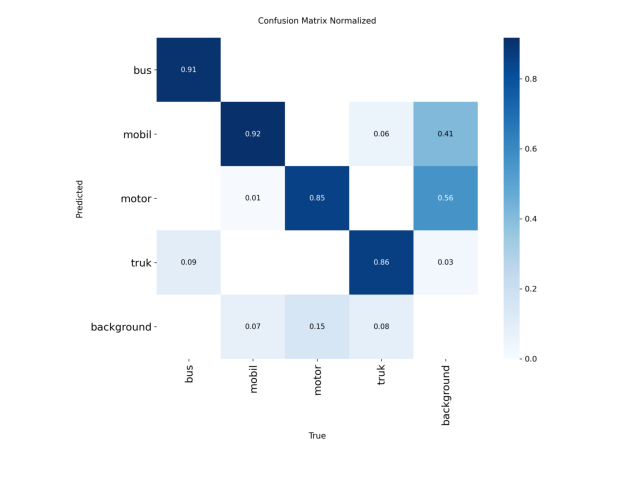

PR_curve.png tidak ditemukan.
F1_curve.png tidak ditemukan.
P_curve.png tidak ditemukan.
R_curve.png tidak ditemukan.


## labels.jpg

Distribusi label pada dataset training, termasuk jumlah objek dan posisi bounding box.

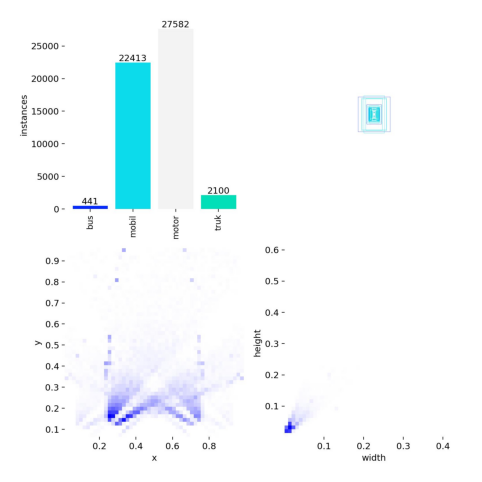

## val_batch0_labels.jpg

Contoh data validasi dengan label asli atau ground truth.

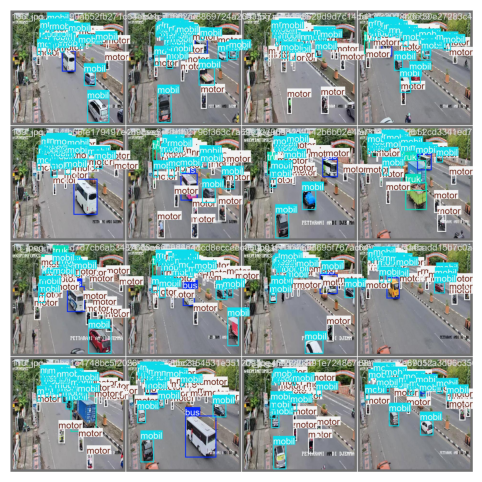

## val_batch0_pred.jpg

Contoh hasil prediksi model pada data validasi.

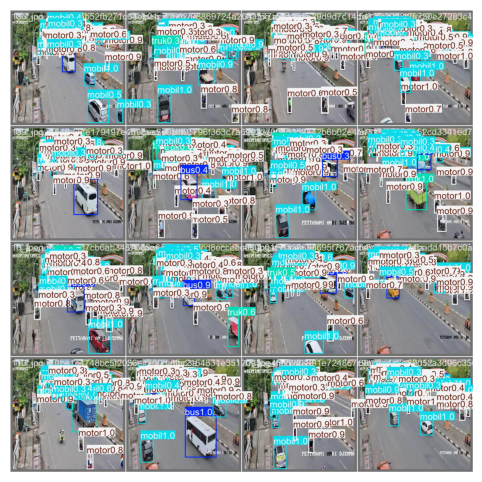

In [67]:
from IPython.display import display, Markdown
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

gambar_penting = {
    "results.png": "Grafik ringkasan hasil training, seperti loss, precision, recall, mAP50, mAP50-95, dan learning rate.",
    "confusion_matrix.png": "Confusion matrix yang menunjukkan kesalahan dan kebenaran klasifikasi antar kelas.",
    "confusion_matrix_normalized.png": "Confusion matrix dalam bentuk normalisasi agar lebih mudah melihat proporsi kesalahan tiap kelas.",
    "PR_curve.png": "Precision-Recall Curve yang menunjukkan hubungan antara precision dan recall model.",
    "F1_curve.png": "F1 Curve yang menunjukkan keseimbangan antara precision dan recall.",
    "P_curve.png": "Precision Curve yang menunjukkan perubahan precision terhadap confidence threshold.",
    "R_curve.png": "Recall Curve yang menunjukkan perubahan recall terhadap confidence threshold.",
    "labels.jpg": "Distribusi label pada dataset training, termasuk jumlah objek dan posisi bounding box.",
    "val_batch0_labels.jpg": "Contoh data validasi dengan label asli atau ground truth.",
    "val_batch0_pred.jpg": "Contoh hasil prediksi model pada data validasi."
}

for nama_file, keterangan in gambar_penting.items():
    path_file = os.path.join(run_dir, nama_file)
    
    if os.path.exists(path_file):
        display(Markdown(f"## {nama_file}"))
        display(Markdown(keterangan))
        
        img = mpimg.imread(path_file)
        
        plt.figure(figsize=(12, 6))
        plt.imshow(img)
        plt.axis("off")
        plt.show();
        
    else:
        print(nama_file, "tidak ditemukan.")

#  Evaluasi Performa Model YOLO

In [77]:
import os
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING"

run_dir = r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\runs\yolo26-cctv"

csv_path = os.path.join(run_dir, "results.csv")

print("CSV path:", csv_path)

CSV path: D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\runs\yolo26-cctv\results.csv


In [78]:
# Load the CSV file into a DataFrame

csv_path = os.path.join(run_dir, "results.csv")

df = pd.read_csv(csv_path)

# Hilangkan spasi di nama kolom
df.columns = df.columns.str.strip()

print("Kolom yang tersedia:")
for kolom in df.columns:
    print(kolom)

df.head()

Kolom yang tersedia:
epoch
time
train/box_loss
train/cls_loss
train/dfl_loss
metrics/precision(B)
metrics/recall(B)
metrics/mAP50(B)
metrics/mAP50-95(B)
val/box_loss
val/cls_loss
val/dfl_loss
lr/pg0
lr/pg1
lr/pg2


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,42.6444,1.91852,3.26080,0.00400,0.07898,0.67917,0.29977,0.20348,1.59502,2.60921,0.00311,0.000410,0.000410,0.000410
1,2,70.4321,1.75946,1.68200,0.00320,0.50467,0.54168,0.50222,0.33804,1.46015,1.41315,0.00274,0.000819,0.000819,0.000819
2,3,97.5284,1.67423,1.39228,0.00296,0.62357,0.56793,0.60673,0.40839,1.50877,1.19458,0.00283,0.001219,0.001219,0.001219
3,4,125.7270,1.63349,1.24698,0.00281,0.68327,0.65958,0.71994,0.52723,1.40125,1.02073,0.00262,0.001213,0.001213,0.001213
4,5,162.6130,1.63339,1.17263,0.00281,0.76575,0.71396,0.76731,0.54564,1.37634,0.92261,0.00255,0.001200,0.001200,0.001200


In [79]:
%matplotlib inline

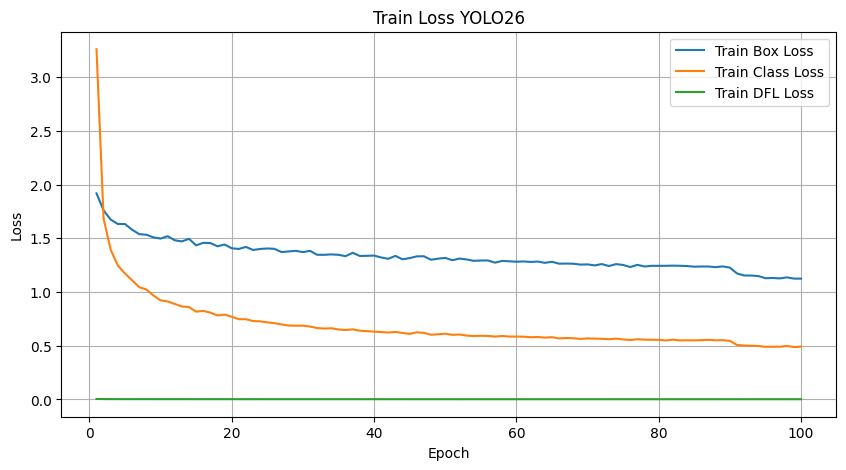

Keterangan:
Train Box Loss  : Mengukur kesalahan model dalam memprediksi posisi dan ukuran bounding box.
Train Class Loss: Mengukur kesalahan model dalam mengklasifikasikan objek ke kelas yang benar.
Train DFL Loss  : Mengukur kesalahan model dalam memperkirakan distribusi bounding box agar lebih presisi.

Interpretasi:
Semakin rendah nilai loss, maka semakin baik proses pembelajaran model.
Jika ketiga loss menurun dan stabil, maka model menunjukkan proses training yang baik.


In [80]:
# Visualisasi loss selama training (Train Loss)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(df["epoch"], df["train/box_loss"], label="Train Box Loss")
plt.plot(df["epoch"], df["train/cls_loss"], label="Train Class Loss")
plt.plot(df["epoch"], df["train/dfl_loss"], label="Train DFL Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train Loss YOLO26")
plt.legend()
plt.grid(True)
plt.show();

print("Keterangan:")
print("Train Box Loss  : Mengukur kesalahan model dalam memprediksi posisi dan ukuran bounding box.")
print("Train Class Loss: Mengukur kesalahan model dalam mengklasifikasikan objek ke kelas yang benar.")
print("Train DFL Loss  : Mengukur kesalahan model dalam memperkirakan distribusi bounding box agar lebih presisi.")
print("")
print("Interpretasi:")
print("Semakin rendah nilai loss, maka semakin baik proses pembelajaran model.")
print("Jika ketiga loss menurun dan stabil, maka model menunjukkan proses training yang baik.")

Folder hasil training:
D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\runs\yolo26-cctv
1. Visualisasi Train Loss:


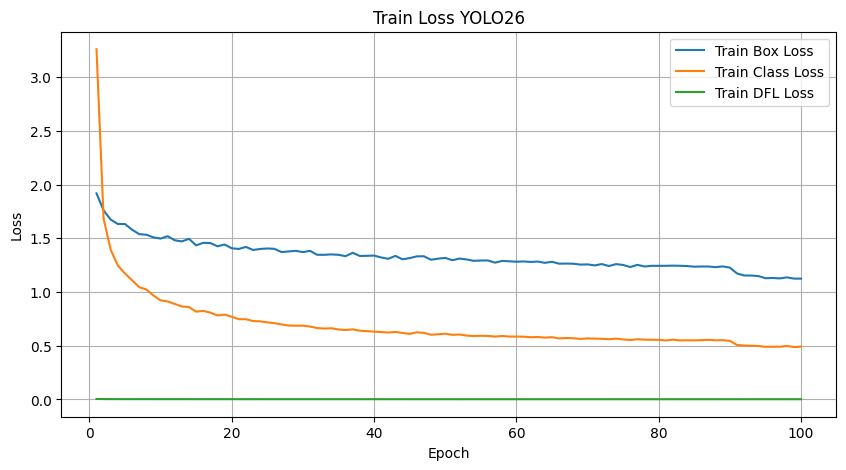

Keterangan Train Loss:
Train Box Loss  : Mengukur kesalahan model dalam memprediksi posisi dan ukuran bounding box.
Train Class Loss: Mengukur kesalahan model dalam mengklasifikasikan objek ke kelas yang benar.
Train DFL Loss  : Mengukur kesalahan model dalam memperkirakan distribusi bounding box agar lebih presisi.

Interpretasi:
Semakin rendah nilai loss, maka semakin baik proses pembelajaran model.
Jika ketiga loss menurun dan stabil, maka model menunjukkan proses training yang baik.


2. Visualisasi Validation Loss:


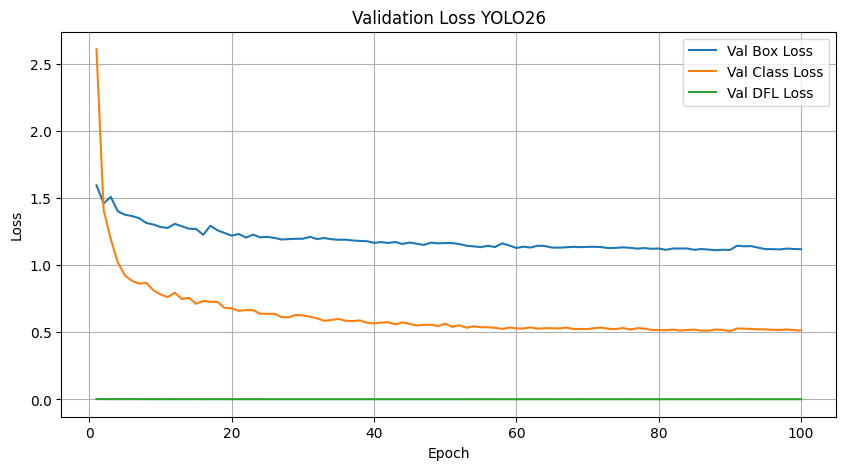

Keterangan Validation Loss:
Val Box Loss   : Mengukur kesalahan posisi bounding box pada data validasi.
Val Class Loss : Mengukur kesalahan klasifikasi objek pada data validasi.
Val DFL Loss   : Mengukur kesalahan presisi distribusi bounding box pada data validasi.

Interpretasi:
Validation loss digunakan untuk melihat kemampuan model pada data yang tidak digunakan langsung saat training.
Jika train loss turun tetapi validation loss naik, maka model berpotensi mengalami overfitting.


3. Visualisasi Precision dan Recall:


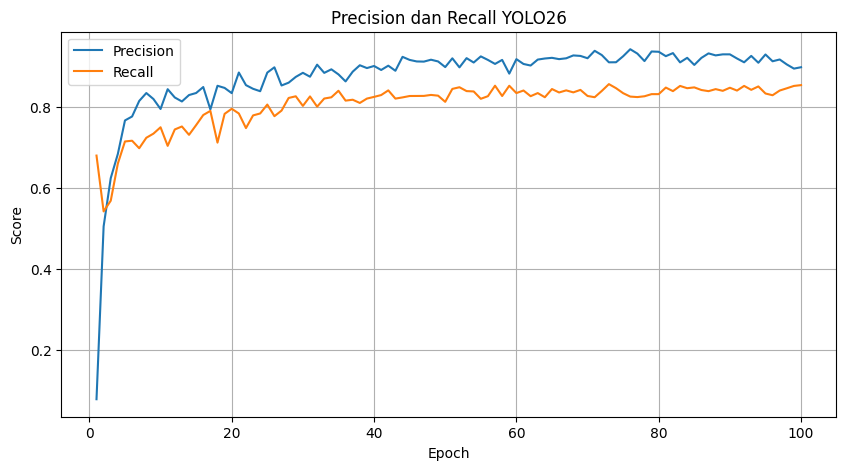

Keterangan Precision dan Recall:
Precision : Mengukur seberapa banyak prediksi model yang benar dari seluruh objek yang diprediksi.
Recall    : Mengukur seberapa banyak objek sebenarnya yang berhasil dideteksi oleh model.

Interpretasi:
Precision tinggi berarti false positive rendah, misalnya bayangan atau orang tidak sering salah terdeteksi sebagai kendaraan.
Recall tinggi berarti false negative rendah, yaitu kendaraan yang terlewat semakin sedikit.
Untuk traffic counting, recall sangat penting karena kendaraan yang tidak terdeteksi dapat menyebabkan hasil counting lebih rendah dari kondisi sebenarnya.


4. Visualisasi mAP50 dan mAP50-95:


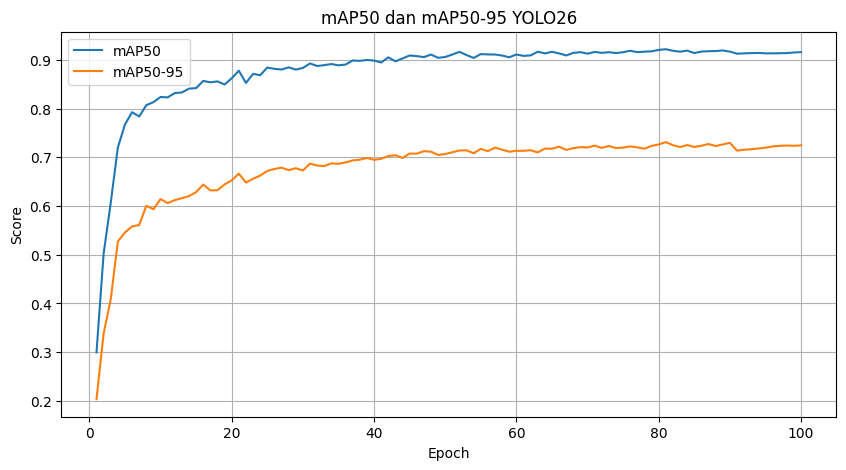

Keterangan mAP:
mAP50    : Mengukur rata-rata akurasi deteksi model pada ambang IoU 50%.
mAP50-95 : Mengukur rata-rata akurasi deteksi model pada ambang IoU 50% sampai 95%.

Interpretasi:
mAP50 menunjukkan kemampuan deteksi objek secara umum.
mAP50-95 lebih ketat karena menilai ketepatan bounding box pada berbagai ambang IoU.
Nilai mAP50 biasanya lebih tinggi daripada mAP50-95, dan itu normal.


5. Visualisasi Learning Rate:


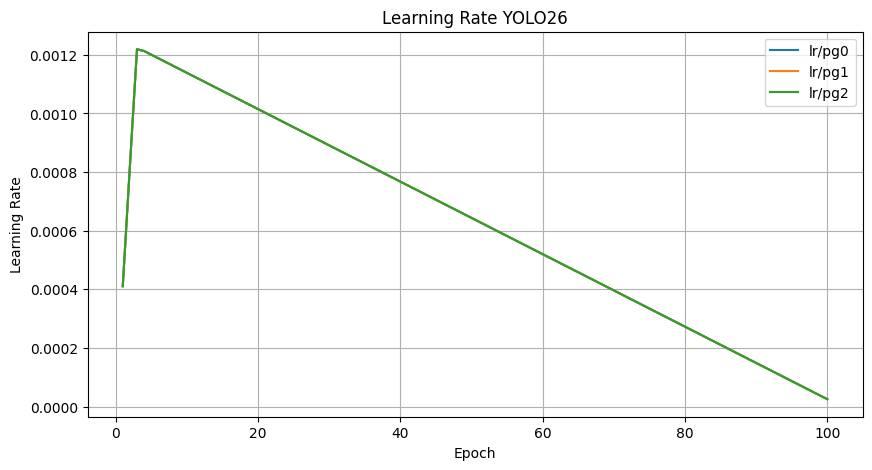

Keterangan Learning Rate:
lr/pg0 : Learning rate untuk kelompok parameter pertama.
lr/pg1 : Learning rate untuk kelompok parameter kedua.
lr/pg2 : Learning rate untuk kelompok parameter ketiga.

Interpretasi:
Learning rate menunjukkan seberapa besar perubahan bobot model saat proses training.
Learning rate yang terlalu besar dapat membuat training tidak stabil, sedangkan terlalu kecil dapat membuat proses belajar menjadi lambat.


In [81]:
import os
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING"
RUNS_DIR = os.path.join(BASE_DIR, "runs")

run_dirs = []

for nama in os.listdir(RUNS_DIR):
    full_path = os.path.join(RUNS_DIR, nama)
    
    if os.path.isdir(full_path) and nama.startswith("yolo26-cctv"):
        run_dirs.append(full_path)

run_dir = max(run_dirs, key=os.path.getmtime)

csv_path = os.path.join(run_dir, "results.csv")

df = pd.read_csv(csv_path)
df.columns = df.columns.str.strip()

print("Folder hasil training:")
print(run_dir)

# 1. Train Loss
print("1. Visualisasi Train Loss:")
plt.figure(figsize=(10, 5))
plt.plot(df["epoch"], df["train/box_loss"], label="Train Box Loss")
plt.plot(df["epoch"], df["train/cls_loss"], label="Train Class Loss")
plt.plot(df["epoch"], df["train/dfl_loss"], label="Train DFL Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train Loss YOLO26")
plt.legend()
plt.grid(True)
plt.show();

print("Keterangan Train Loss:")
print("Train Box Loss  : Mengukur kesalahan model dalam memprediksi posisi dan ukuran bounding box.")
print("Train Class Loss: Mengukur kesalahan model dalam mengklasifikasikan objek ke kelas yang benar.")
print("Train DFL Loss  : Mengukur kesalahan model dalam memperkirakan distribusi bounding box agar lebih presisi.")
print("")
print("Interpretasi:")
print("Semakin rendah nilai loss, maka semakin baik proses pembelajaran model.")
print("Jika ketiga loss menurun dan stabil, maka model menunjukkan proses training yang baik.")

# 2. Validation Loss
print("\n\n2. Visualisasi Validation Loss:")
plt.figure(figsize=(10, 5))
plt.plot(df["epoch"], df["val/box_loss"], label="Val Box Loss")
plt.plot(df["epoch"], df["val/cls_loss"], label="Val Class Loss")
plt.plot(df["epoch"], df["val/dfl_loss"], label="Val DFL Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Validation Loss YOLO26")
plt.legend()
plt.grid(True)
plt.show();

print("Keterangan Validation Loss:")
print("Val Box Loss   : Mengukur kesalahan posisi bounding box pada data validasi.")
print("Val Class Loss : Mengukur kesalahan klasifikasi objek pada data validasi.")
print("Val DFL Loss   : Mengukur kesalahan presisi distribusi bounding box pada data validasi.")
print("\nInterpretasi:")
print("Validation loss digunakan untuk melihat kemampuan model pada data yang tidak digunakan langsung saat training.")
print("Jika train loss turun tetapi validation loss naik, maka model berpotensi mengalami overfitting.")

# 3. Precision dan Recall
print("\n\n3. Visualisasi Precision dan Recall:")
plt.figure(figsize=(10, 5))
plt.plot(df["epoch"], df["metrics/precision(B)"], label="Precision")
plt.plot(df["epoch"], df["metrics/recall(B)"], label="Recall")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Precision dan Recall YOLO26")
plt.legend()
plt.grid(True)
plt.show();

print("Keterangan Precision dan Recall:")
print("Precision : Mengukur seberapa banyak prediksi model yang benar dari seluruh objek yang diprediksi.")
print("Recall    : Mengukur seberapa banyak objek sebenarnya yang berhasil dideteksi oleh model.")
print("\nInterpretasi:")
print("Precision tinggi berarti false positive rendah, misalnya bayangan atau orang tidak sering salah terdeteksi sebagai kendaraan.")
print("Recall tinggi berarti false negative rendah, yaitu kendaraan yang terlewat semakin sedikit.")
print("Untuk traffic counting, recall sangat penting karena kendaraan yang tidak terdeteksi dapat menyebabkan hasil counting lebih rendah dari kondisi sebenarnya.")

# 4. mAP
print("\n\n4. Visualisasi mAP50 dan mAP50-95:")
plt.figure(figsize=(10, 5))
plt.plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
plt.plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("mAP50 dan mAP50-95 YOLO26")
plt.legend()
plt.grid(True)
plt.show();
print("Keterangan mAP:")
print("mAP50    : Mengukur rata-rata akurasi deteksi model pada ambang IoU 50%.")
print("mAP50-95 : Mengukur rata-rata akurasi deteksi model pada ambang IoU 50% sampai 95%.")
print("\nInterpretasi:")
print("mAP50 menunjukkan kemampuan deteksi objek secara umum.")
print("mAP50-95 lebih ketat karena menilai ketepatan bounding box pada berbagai ambang IoU.")
print("Nilai mAP50 biasanya lebih tinggi daripada mAP50-95, dan itu normal.")

# 5. Learning Rate
print("\n\n5. Visualisasi Learning Rate:")
plt.figure(figsize=(10, 5))
plt.plot(df["epoch"], df["lr/pg0"], label="lr/pg0")
plt.plot(df["epoch"], df["lr/pg1"], label="lr/pg1")
plt.plot(df["epoch"], df["lr/pg2"], label="lr/pg2")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Learning Rate YOLO26")
plt.legend()
plt.grid(True)
plt.show();

print("Keterangan Learning Rate:")
print("lr/pg0 : Learning rate untuk kelompok parameter pertama.")
print("lr/pg1 : Learning rate untuk kelompok parameter kedua.")
print("lr/pg2 : Learning rate untuk kelompok parameter ketiga.")
print("\nInterpretasi:")
print("Learning rate menunjukkan seberapa besar perubahan bobot model saat proses training.")
print("Learning rate yang terlalu besar dapat membuat training tidak stabil, sedangkan terlalu kecil dapat membuat proses belajar menjadi lambat.")

In [88]:
from ultralytics import YOLO

# Load model hasil training
model = YOLO(r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\runs\yolo26-cctv\weights\best.pt")

# Testing pada data video lokal
results = model.predict(
    source=r"D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\(test)cctv-bus-truk.mp4",
    save=True,           # Simpan hasil video
    conf=0.70,           # Threshold minimum agar objek terdeteksi
    show_conf=True,      # Menampilkan skor kepercayaan
    line_width=1,        # Garis bounding box lebih tipis
    device=0             # Pakai GPU
)


WARNING 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/585) D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\(test)cctv-bus-truk.mp4: 384x640 10 mobils, 9 motors, 35.8ms
video 1/1 (frame 2/585) D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\(test)cctv-bus-truk.mp4: 384x640 10 mobils, 10 motors, 9.9ms
video 1/1 (frame 3/585) D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAFFIC COUNTING\(test)cctv-bus-truk.mp4: 384x640 14 mobils, 9 motors, 9.7ms
video 1/1 (frame 4/585) D:\1-Kuliah\SEKRIPSI\0. PROGRAM TRAF